<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_11/dataset_pbl/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 2**
## **langkah 1 - Ilustrasi Data Non-Linier**
Data yang terpisah secara tidak linier menjadi masalah pada model SVM. Oleh karena itu, kernel menjadi sebuah kebutuhan bagi SVM untuk melakukan fitting pada hubungan non-linier dengan sebuah classifier linier.

### **Langkah 1a - Import Library**

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.0 MB/s  0:00:00


### **Langkah 1b - Buat Kembali Fungsi Plotting**

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
                levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                    model.support_vectors_[:, 1],
                    s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### **Langkah 1c - Buat Data Dummy Non-Linear**

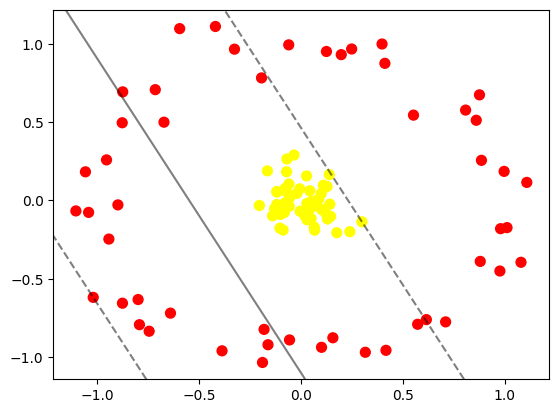

In [3]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

Berdasarkan contoh data di atas, tidak ditemukan sebuah garis pemisah linier yang mampu berperan sebagai pemisah data. Oleh karena itu, proyeksi (sudut pandang) lain terhadap data diperlukan supaya data dapat terpisahkan dengan jelas. Pada kegiatan ini, proyeksi yang digunakan adalah proyeksi berbasis radial.

In [4]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Hitung nilai r
r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
          X=fixed(X), y=fixed(y))

## **Langkah 2 - Fitting Model**

Walaupun data dapat ditampilkan secara terpisah. Proyeksi titik data sejumlah N ke dalan suatu dimensi N menyebabkan beban komputasi juga bertambah. Untuk mengatasi hal ini, kernel radial basis function (RBF) pada Scikit-Learn digunakan.

In [5]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

Plot hasil decision boundaries dari kernel RBF

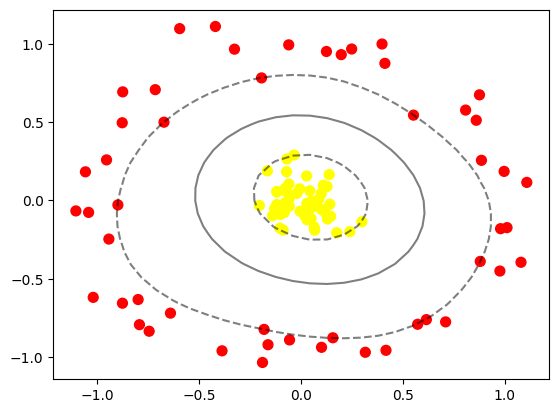

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')

## **Langkah 3 - Implementasi SVM Pada Dataset Sleep Health**

Sekarang kita akan menerapkan model Support Vector Machine (SVM) menggunakan dataset pilihan Anda: `Sleep_health_and_lifestyle_dataset.csv`.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

# Memuat dataset
df = pd.read_csv('/content/Sleep_health_and_lifestyle_dataset.csv')
display(df.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


### **Langkah 3a - Preprocessing Data**

Kita akan menangani nilai yang hilang pada kolom target (misalnya `Sleep Disorder` diisi dengan 'None' jika kosong), melakukan encoding untuk fitur kategori, dan membagi data menjadi set pelatihan dan pengujian.

In [8]:
# Menangani nilai kosong pada target
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# Menghapus kolom identifier yang tidak relevan untuk klasifikasi
data_clean = df.drop(columns=['Person ID'])

# Memisahkan tekanan darah menjadi Systolic dan Diastolic
if 'Blood Pressure' in data_clean.columns:
    data_clean[['Systolic_BP', 'Diastolic_BP']] = data_clean['Blood Pressure'].str.split('/', expand=True).astype(float)
    data_clean = data_clean.drop(columns=['Blood Pressure'])

# Encoding fitur kategori menggunakan LabelEncoder
label_encoders = {}
categorical_cols = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']

for col in categorical_cols:
    if col in data_clean.columns:
        le = LabelEncoder()
        data_clean[col] = le.fit_transform(data_clean[col])
        label_encoders[col] = le

# Memisahkan fitur (X) dan Target (y)
# Target: Sleep Disorder (None, Sleep Apnea, Insomnia)
X_sleep = data_clean.drop(columns=['Sleep Disorder'])
y_sleep = data_clean['Sleep Disorder']

# Membagi dataset
X_train, X_test, y_train, y_test = train_test_split(X_sleep, y_sleep, test_size=0.2, random_state=42, stratify=y_sleep)

# Standarisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Ukuran data training: {X_train_scaled.shape}")
print(f"Ukuran data testing: {X_test_scaled.shape}")

Ukuran data training: (299, 12)
Ukuran data testing: (75, 12)


### **Langkah 3b - Fitting SVM dengan Kernel RBF**

Mari latih model `SVC` dengan kernel `rbf` pada dataset ini dan evaluasi kinerjanya.

In [9]:
# Inisialisasi model SVC dengan kernel RBF
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Prediksi data pengujian
y_pred = svm_model.predict(X_test_scaled)

# Evaluasi Model
print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("\nLaporan Klasifikasi:")
target_names = list(label_encoders['Sleep Disorder'].classes_)
print(classification_report(y_test, y_pred, target_names=target_names))

Akurasi Model: 0.9733333333333334

Laporan Klasifikasi:
              precision    recall  f1-score   support

    Insomnia       1.00      0.87      0.93        15
        None       1.00      1.00      1.00        44
 Sleep Apnea       0.89      1.00      0.94        16

    accuracy                           0.97        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.98      0.97      0.97        75



###